# Exploratory Analysis of Distribution Shift — SIVEP-Gripe (2019–2026)

**Goal:** visualize and quantify the distribution shifts caused by the COVID-19 pandemic in the Severe Acute Respiratory Syndrome (SARS/SRAG) records of SIVEP-Gripe, from July/2019 to February/2026.

**Dataset:** `src/data/SRAG/srag.parquet` — ~4.1 million records  
**Variables:** `DT_NOTIFIC`, `EVOLUCAO`, `CS_RACA`, `CS_SEXO`, `NU_IDADE_N`  
**Epidemiological periods:** pre-pandemic | acute pandemic 1 | acute pandemic 2 | transition | endemic

## Section 1: Setup and Data Loading

We import the libraries, set the visual style (high resolution, colorblind-safe palette) and define global constants reused by every figure.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
import seaborn as sns
from pathlib import Path

# ── Estilo ──────────────────────────────────────────────────────────────────
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'figure.dpi': 120,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
})

# ── Period palette (seaborn 'deep', 5 colors) ─────────────────────────────
PERIOD_ORDER = ['pre-pandemic', 'acute pandemic 1', 'acute pandemic 2', 'transition', 'endemic']
_pal = sns.color_palette('deep', 5)
PERIOD_COLORS = dict(zip(PERIOD_ORDER, _pal))

PERIOD_SPANS = [
    ('2019-07-01', '2020-03-01', 'pre-pandemic'),
    ('2020-03-01', '2022-01-01', 'acute pandemic 1'),
    ('2022-01-01', '2023-01-01', 'acute pandemic 2'),
    ('2023-01-01', '2024-01-01', 'transition'),
    ('2024-01-01', '2026-03-01', 'endemic'),
]
VLINES = [
    (pd.Timestamp('2020-03-01'), 'Mar/2020'),
    (pd.Timestamp('2022-01-01'), 'Jan/2022'),
    (pd.Timestamp('2023-01-01'), 'Jan/2023'),
    (pd.Timestamp('2024-01-01'), 'Jan/2024'),
]

# ── Date formatter (English month abbreviations) ────────────────────────────
MONTH_EN = {1:'Jan',2:'Feb',3:'Mar',4:'Apr',5:'May',6:'Jun',
            7:'Jul',8:'Aug',9:'Sep',10:'Oct',11:'Nov',12:'Dec'}

def fmt_date(x, pos):
    try:
        dt = mdates.num2date(x)
        return f'{MONTH_EN[dt.month]}/{dt.year}'
    except Exception:
        return ''

# ── Helper: adds period shading to an axis ──────────────────────────────────
def add_period_spans(ax):
    for start, end, name in PERIOD_SPANS:
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end),
                   alpha=0.20, color=PERIOD_COLORS[name])

def add_vlines(ax):
    for ts, label in VLINES:
        ax.axvline(ts, color='#555555', linestyle='--', linewidth=1.2, alpha=0.8)
        ax.text(ts, 0.97, label, rotation=90, va='top', ha='right', fontsize=9,
                color='#555555', transform=ax.get_xaxis_transform())

def fmt_xaxis(ax):
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(FuncFormatter(fmt_date))
    plt.setp(ax.xaxis.get_majorticklabels(), rotation=45, ha='right')

# ── Locate the project root (search upwards for pyproject.toml) ────────────
def _find_project_root(marker: str = 'pyproject.toml') -> Path:
    current = Path('.').resolve()
    for candidate in [current, *current.parents]:
        if (candidate / marker).exists():
            return candidate
    return current

BASE      = _find_project_root()
FIG_DIR   = BASE / 'src' / 'notebooks' / 'figures'
TABLE_DIR = BASE / 'src' / 'notebooks' / 'tables'
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

### 1.2 Loading and initial inspection

We load the parquet files and check shape, dtypes, missing values and temporal coverage. Note: `NU_IDADE_N` is stored as `Decimal` in the parquet — it is converted in Section 2.


In [2]:
RAW_DIR = BASE / 'src' / 'data' / 'SRAG' / 'raw'
COLS = ['DT_NOTIFIC', 'EVOLUCAO', 'CS_RACA', 'CS_SEXO', 'NU_IDADE_N']

# Read and concatenate the required columns from all yearly raw parquets
raw_files = sorted(RAW_DIR.glob('*.parquet'))
df_raw = pd.concat(
    (pd.read_parquet(f, columns=COLS) for f in raw_files),
    ignore_index=True,
)

# Normalize the schema expected by the following cells:
# EVOLUCAO comes as a string in the raw files → convert to a nullable integer (Int64),
# since the death mapping uses integer keys {1, 2}.
df_raw['EVOLUCAO'] = pd.to_numeric(df_raw['EVOLUCAO'], errors='coerce').astype('Int64')
df_raw['DT_NOTIFIC'] = pd.to_datetime(df_raw['DT_NOTIFIC'], errors='coerce')

print(f'Files read: {len(raw_files)}')
print(f'Shape: {df_raw.shape}')
print(f'\nDtypes:\n{df_raw.dtypes}')
print(f'\nMissing values per column:\n{df_raw.isnull().sum()}')

min_dt = df_raw['DT_NOTIFIC'].min()
max_dt = df_raw['DT_NOTIFIC'].max()
print(f'\nRange temporal: {min_dt} → {max_dt}')

print('\nRecords per year:')
print(df_raw['DT_NOTIFIC'].dt.year.value_counts().sort_index().to_string())

print('\nFirst rows:')
df_raw.head()


Files read: 8
Shape: (4537980, 5)

Dtypes:
DT_NOTIFIC    datetime64[ns]
EVOLUCAO               Int64
CS_RACA                  str
CS_SEXO                  str
NU_IDADE_N            object
dtype: object



Missing values per column:
DT_NOTIFIC         0
EVOLUCAO      335666
CS_RACA        45141
CS_SEXO            0
NU_IDADE_N         0
dtype: int64

Range temporal: 2018-12-30 00:00:00 → 2026-05-17 00:00:00

Records per year:


DT_NOTIFIC
2018          3
2019      48634
2020    1148787
2021    1773875
2022     582656
2023     284383
2024     268519
2025     334514
2026      96609

First rows:


,DT_NOTIFIC,EVOLUCAO,CS_RACA,CS_SEXO,NU_IDADE_N
0,2019-07-22,1,4,F,35
1,2019-07-17,1,1,F,46
2,2019-07-08,1,4,F,21
3,2019-10-07,1,4,F,24
4,2019-04-29,1,NaN,F,78


## Section 2: Analytical Preparation

We create the derived columns needed for the analyses:
- `year_month`: monthly granularity for temporal grouping
- `death`: boolean based on `EVOLUCAO` (True=death, False=recovery, NaN=other)
- `period`: **five epidemiological phases** based on pandemic milestones
- `race`: readable labels for `CS_RACA`
- `age`: numeric age, with implausible ages removed

### Rationale for the Time Windows

The five periods reflect distinct epidemiological phases of COVID-19 in Brazil:

- **pre-pandemic** (Jul/2019 – Feb/2020): baseline of seasonal SARS, mostly influenza and other respiratory viruses
- **acute pandemic 1** (Mar/2020 – Dec/2021): pre-Omicron era — original SARS-CoV-2 strains and the Alpha, Gamma (P.1) and Delta variants, with high absolute mortality
- **acute pandemic 2** (Jan/2022 – Dec/2022): Omicron era — BA.1, BA.2 and BA.5 variants; surge of cases with lower proportional mortality and an age shift towards younger populations
- **transition** (Jan/2023 – Dec/2023): progressive decline until the WHO declared the end of the Public Health Emergency of International Concern (PHEIC) in May/2023; hybrid pattern with residual COVID-19 circulation and the return of influenza
- **endemic** (Jan/2024 – Feb/2026): new post-pandemic pattern, with COVID-19 integrated into the seasonal SARS calendar

This split is more granular than the previous one (4 periods), specifically to separate the pre-Omicron impact (**acute pandemic 1**) from the Omicron impact (**acute pandemic 2**), which have very different epidemiological dynamics: higher transmissibility, lower virulence per case and a different age profile of deaths.

In [3]:
df = df_raw.copy()

# 1. Make sure DT_NOTIFIC is a datetime
df['DT_NOTIFIC'] = pd.to_datetime(df['DT_NOTIFIC'], errors='coerce')

# 2. Filter to the analysis period (Jul/2019 – Feb/2026)
n_before = len(df)
df = df[
    (df['DT_NOTIFIC'] >= pd.Timestamp('2019-07-01')) &
    (df['DT_NOTIFIC'] <= pd.Timestamp('2026-02-28'))
].copy()
print(f'Records in the Jul/2019–Feb/2026 period: {len(df):,}  (removed: {n_before - len(df):,})')

# 3. year_month as Period[M]
df['year_month'] = df['DT_NOTIFIC'].dt.to_period('M')

# 4. death: True=EVOLUCAO 2, False=EVOLUCAO 1, NaN for 3 and 9
df['death'] = df['EVOLUCAO'].map({1: False, 2: True})

# 5. period: five epidemiological bins (closed on the left, open on the right)
period_bins = [
    pd.Timestamp('2019-07-01'),
    pd.Timestamp('2020-03-01'),
    pd.Timestamp('2022-01-01'),
    pd.Timestamp('2023-01-01'),
    pd.Timestamp('2024-01-01'),
    pd.Timestamp('2026-03-01'),
]
df['period'] = pd.cut(
    df['DT_NOTIFIC'],
    bins=period_bins,
    labels=PERIOD_ORDER,
    right=False,
    ordered=True,
)

# 6. Race/color with readable labels (in English)
RACE_MAP = {'1':'White','2':'Black','3':'Asian','4':'Mixed','5':'Indigenous','9':'Unknown'}
df['race'] = df['CS_RACA'].map(RACE_MAP)

# 7. Numeric age (NU_IDADE_N is stored as Decimal → convert via string)
df['age'] = pd.to_numeric(df['NU_IDADE_N'].astype(str), errors='coerce')
mask_invalid = (df['age'] < 0) | (df['age'] > 110)
n_invalid = int(mask_invalid.sum())
df.loc[mask_invalid, 'age'] = np.nan
print(f'Implausible ages (< 0 or > 110) removed: {n_invalid:,}')

# 8. Summary per period
print('\nSummary per period:')
summary = df.groupby('period', observed=False).agg(
    N=('DT_NOTIFIC', 'count'),
    dt_min=('DT_NOTIFIC', 'min'),
    dt_max=('DT_NOTIFIC', 'max'),
)
summary

Records in the Jul/2019–Feb/2026 period: 4,440,038  (removed: 97,942)


Implausible ages (< 0 or > 110) removed: 191

Summary per period:


,N,dt_min,dt_max
period,,,
pre-pandemic,23721,2019-07-01,2020-02-29
acute pandemic 1,2918458,2020-03-01,2021-12-31
acute pandemic 2,582656,2022-01-01,2022-12-31
transition,284383,2023-01-01,2023-12-31
endemic,630820,2024-01-01,2026-02-28


## Section 3: Figure 1 — Time Series of the Case Fatality Rate

We compute the crude weekly case fatality rate: deaths / (deaths + recoveries), excluding records with an unknown outcome (`EVOLUCAO` 3 or 9).

The dashed vertical lines mark the period cuts; the shading visually separates the epidemiological regimes.


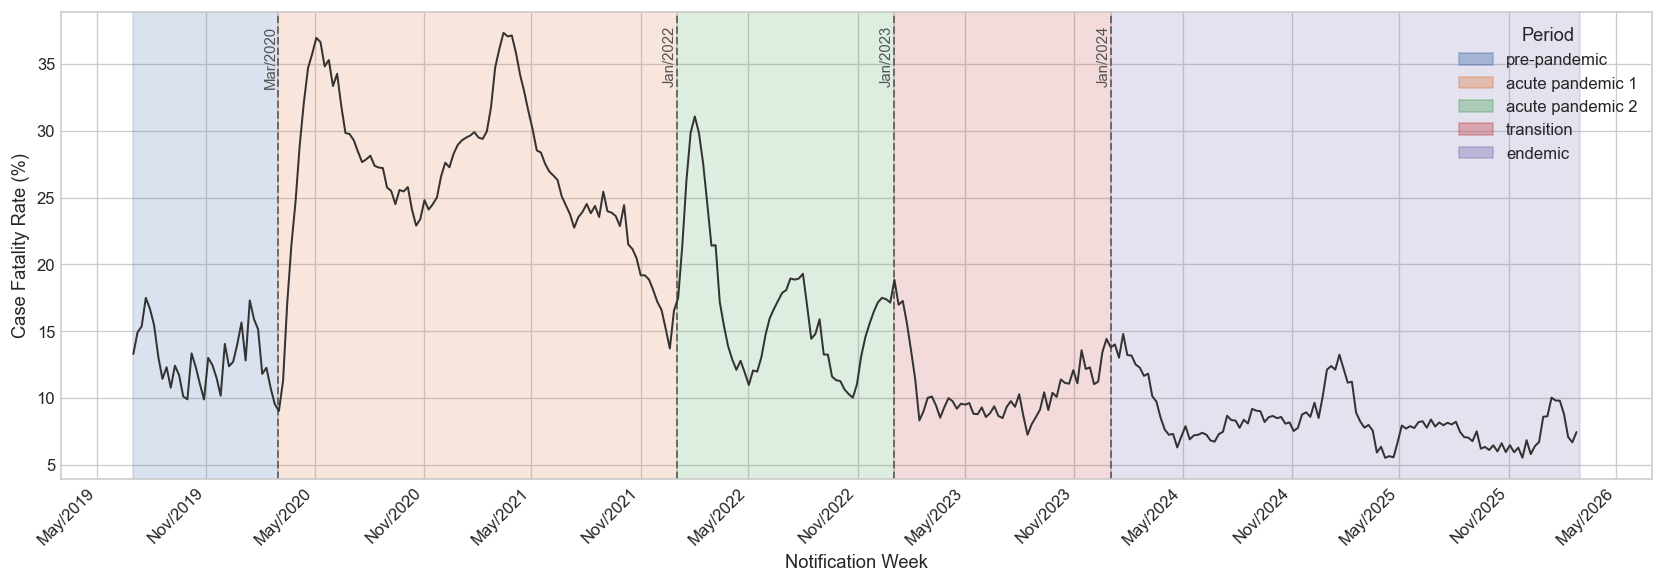

In [4]:
# Weekly grouping: count() ignores NaN → counts only defined outcomes (EVOLUCAO 1 or 2)
df['year_week'] = df['DT_NOTIFIC'].dt.to_period('W')

weekly = (
    df.groupby('year_week')['death']
    .agg(cases='count', deaths='sum')
    .reset_index()
)
weekly['cfr'] = weekly['deaths'] / weekly['cases']
weekly['dt'] = weekly['year_week'].dt.start_time

fig, ax = plt.subplots(figsize=(14, 5))
add_period_spans(ax)
ax.plot(weekly['dt'], weekly['cfr'] * 100,
        color='#333333', linewidth=1.2, zorder=3)
add_vlines(ax)
fmt_xaxis(ax)

ax.set_ylabel('Case Fatality Rate (%)')
ax.set_xlabel('Notification Week')

# Manual period legend
handles = [plt.Rectangle((0,0),1,1, color=PERIOD_COLORS[p], alpha=0.4)
           for p in PERIOD_ORDER]
ax.legend(handles, PERIOD_ORDER, loc='upper right', title='Period', framealpha=0.9)

plt.tight_layout()
out1 = FIG_DIR / 'fig1_cfr_temporal.png'
plt.savefig(out1, dpi=120, bbox_inches='tight')
plt.show()

## Section 4: Figure 2 — Time Series of the Median Age of Deaths

We analyze how the age distribution of deaths evolves over time. The shaded band is the interquartile range (P25–P75), capturing the spread beyond the median.


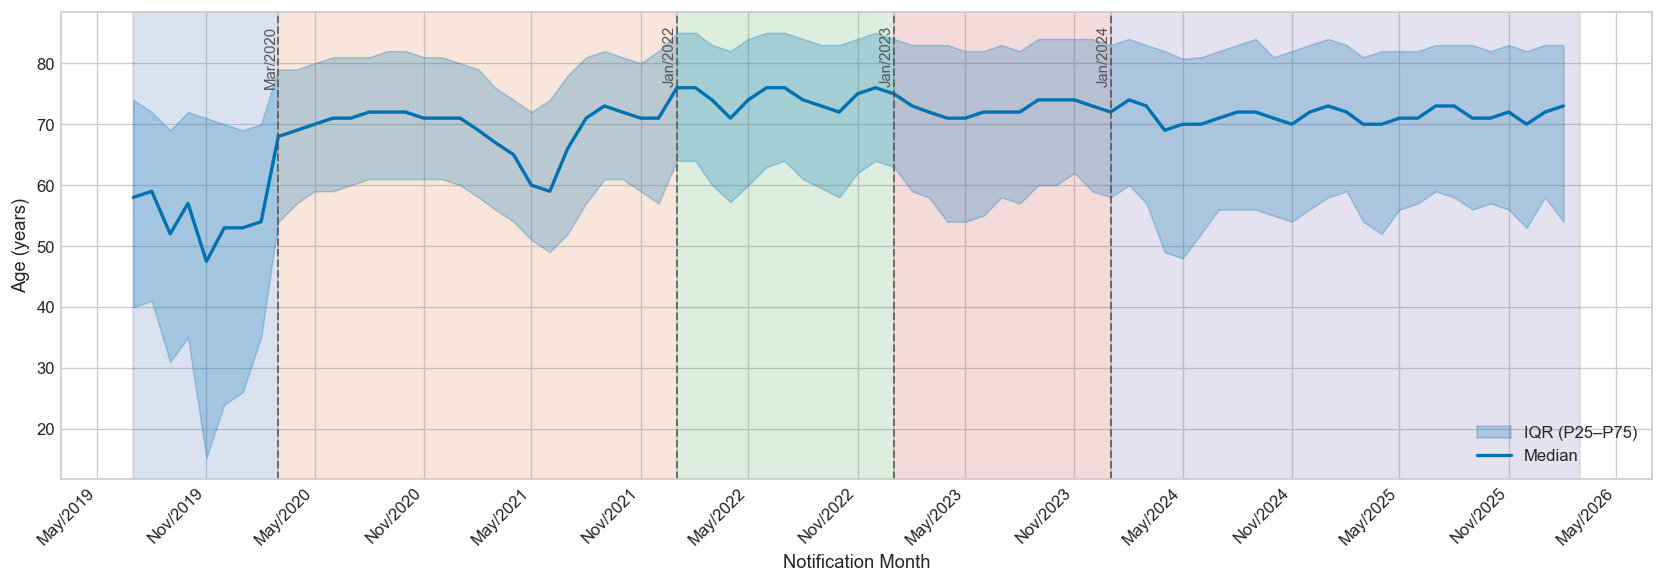

In [5]:
df_deaths = df[df['death'] == True].copy()

age_monthly = (
    df_deaths.groupby('year_month')['age']
    .describe(percentiles=[0.25, 0.5, 0.75])
    [['25%', '50%', '75%']]
    .rename(columns={'25%': 'p25', '50%': 'median', '75%': 'p75'})
    .reset_index()
)
age_monthly['dt'] = age_monthly['year_month'].dt.to_timestamp()

fig, ax = plt.subplots(figsize=(14, 5))
add_period_spans(ax)

ax.fill_between(age_monthly['dt'], age_monthly['p25'], age_monthly['p75'],
                alpha=0.25, color='#0072B2', label='IQR (P25–P75)')
ax.plot(age_monthly['dt'], age_monthly['median'],
        color='#0072B2', linewidth=2, label='Median')

add_vlines(ax)
fmt_xaxis(ax)

ax.set_ylabel('Age (years)')
ax.set_xlabel('Notification Month')
ax.legend(loc='lower right', framealpha=0.9)

plt.tight_layout()
out2 = FIG_DIR / 'fig2_age_deaths_temporal.png'
plt.savefig(out2, dpi=120, bbox_inches='tight')
plt.show()

## Section 5: Figure 3 — Age ECDFs per Period (Cases)

The Empirical Cumulative Distribution Function (ECDF) allows a visual comparison of the age distribution of cases across the five periods. Any horizontal displacement signals a distribution shift in the `age` variable.

The maximum difference between the **pre-pandemic** and **acute pandemic 1** CDFs is the strongest comparison of the initial shift — when SARS-CoV-2 drastically displaced the age profile of hospitalized cases. The Kolmogorov-Smirnov D statistic quantifies this displacement.

For efficiency with ~4M records, we sample up to 100,000 records per period (fixed seed for reproducibility).

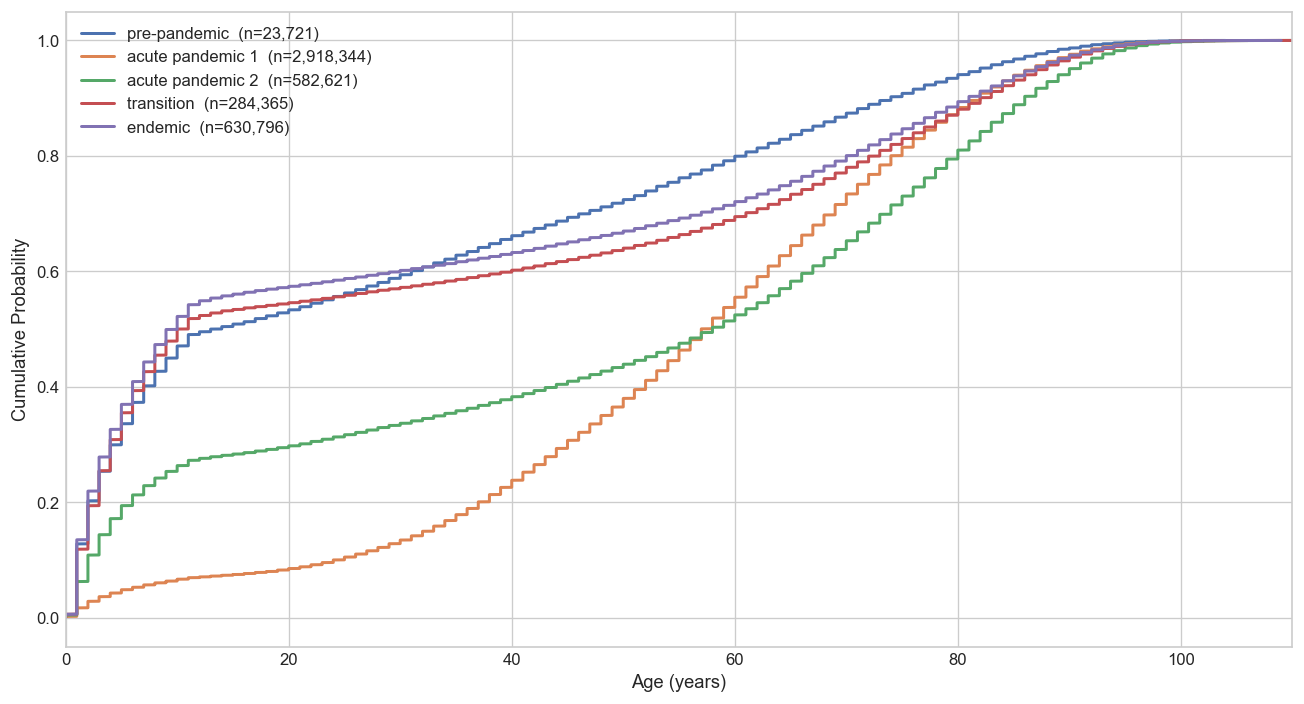

In [6]:
MAX_SAMPLE = 100_000

fig, ax = plt.subplots(figsize=(11, 6))

ecdf_cases = {}
for period in PERIOD_ORDER:
    subset = df[df['period'] == period]['age'].dropna()
    n_orig = len(subset)
    if n_orig > MAX_SAMPLE:
        subset = subset.sample(MAX_SAMPLE, random_state=42)
    x = np.sort(subset.values)
    y = np.arange(1, len(x) + 1) / len(x)
    ecdf_cases[period] = (x, y, n_orig)
    ax.plot(x, y, label=f'{period}  (n={n_orig:,})',
            color=PERIOD_COLORS[period], linewidth=1.8)

ax.set_xlabel('Age (years)')
ax.set_ylabel('Cumulative Probability')
ax.set_xlim(0, 110)
ax.legend(loc='upper left', framealpha=0.9)

plt.tight_layout()
out3 = FIG_DIR / 'fig3_cdf_age_periods.png'
plt.savefig(out3, dpi=120, bbox_inches='tight')
plt.show()

## Section 6: Comparative Descriptive Table

We gather the main statistics of each period in a single DataFrame: volume, case fatality, age distribution and demographic composition (sex and race/color).


In [7]:
rows = []
for period in PERIOD_ORDER:
    sub = df[df['period'] == period]
    n_total    = len(sub)
    n_defined = int(sub['death'].notna().sum())
    n_deaths   = int(sub['death'].sum())
    cfr = n_deaths / n_defined * 100 if n_defined > 0 else np.nan

    age_mean   = sub['age'].mean()
    age_median = sub['age'].median()
    age_std     = sub['age'].std()

    age_median_deaths  = sub.loc[sub['death'] == True,  'age'].median()
    age_median_survivors = sub.loc[sub['death'] == False, 'age'].median()

    sex = sub['CS_SEXO'].value_counts(normalize=True) * 100
    race = sub['race'].value_counts(normalize=True) * 100

    row = {
        'N Total':               n_total,
        'N Defined Outcome':     n_defined,
        'N Deaths':              n_deaths,
        'Case Fatality (%)':     round(cfr, 1),
        'Mean Age':              round(age_mean, 1),
        'Median Age':            round(age_median, 1),
        'Age SD':                round(age_std, 1),
        'Median Age Deaths':     round(age_median_deaths, 1),
        'Median Age Non-Deaths': round(age_median_survivors, 1),
        'Sex M (%)':             round(sex.get('M', 0), 1),
        'Sex F (%)':             round(sex.get('F', 0), 1),
        'Sex Unknown (%)':       round(sex.get('I', 0), 1),
    }
    for r in ['White', 'Black', 'Asian', 'Mixed', 'Indigenous', 'Unknown']:
        row[f'Race {r} (%)'] = round(race.get(r, 0.0), 1)
    rows.append({'Period': period, **row})

table = pd.DataFrame(rows).set_index('Period')
csv_path = TABLE_DIR / 'table_descriptive_periods.csv'
table.to_csv(csv_path)
table.T

Period,pre-pandemic,acute pandemic 1,acute pandemic 2,transition,endemic
N Total,23721.0,2918458.0,582656.0,284383.0,630820.0
N Defined Outcome,21487.0,2596026.0,506356.0,255459.0,566923.0
N Deaths,2820.0,750997.0,98073.0,26488.0,45723.0
Case Fatality (%),13.1,28.9,19.4,10.4,8.1
Mean Age,28.8,54.9,48.5,32.8,30.6
Median Age,14.0,58.0,58.0,11.0,10.0
Age SD,28.9,22.4,32.4,33.3,32.6
Median Age Deaths,57.0,68.0,75.0,73.0,71.0
Median Age Non-Deaths,10.0,53.0,48.0,8.0,8.0
Sex M (%),51.0,54.4,50.4,51.7,51.6


## Section 7: Case Fatality by Race/Color over Time

This figure is central to the **fairness** argument: it shows whether the pandemic disproportionately affected specific racial groups. The 3-month moving average smooths month-to-month volatility while preserving trends.


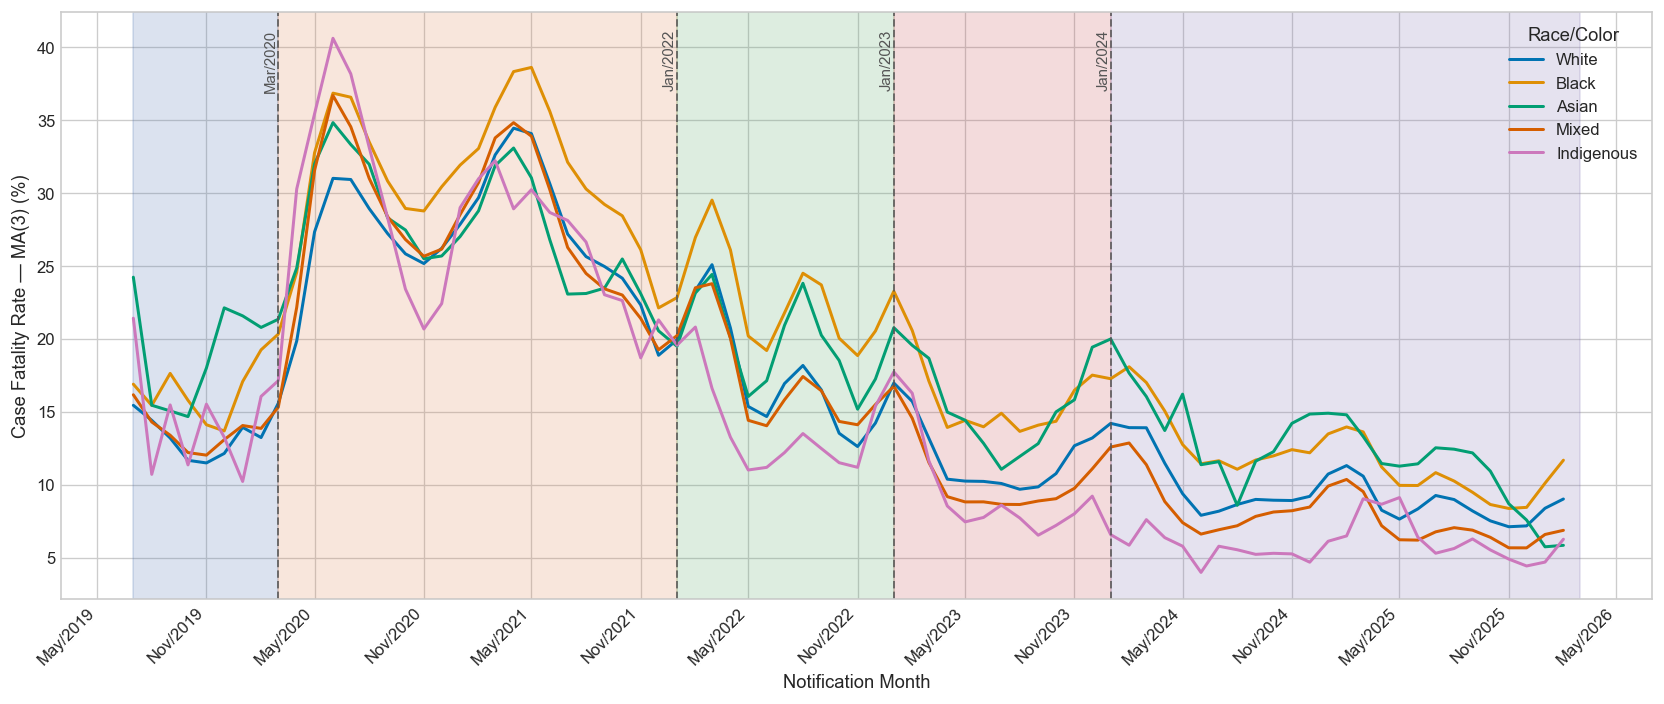

In [8]:
RACES_PLOT  = ['White', 'Black', 'Asian', 'Mixed', 'Indigenous']
RACE_COLORS = dict(zip(RACES_PLOT,
                       sns.color_palette('colorblind', len(RACES_PLOT))))

df_race = df[df['death'].notna() & df['race'].isin(RACES_PLOT)].copy()

monthly_race = (
    df_race.groupby(['year_month', 'race'], observed=True)['death']
    .agg(cases='count', deaths='sum')
    .reset_index()
)
monthly_race['cfr'] = monthly_race['deaths'] / monthly_race['cases']
monthly_race['dt'] = monthly_race['year_month'].dt.to_timestamp()

pivot  = monthly_race.pivot(index='dt', columns='race', values='cfr')
smooth = pivot.rolling(3, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(14, 6))
add_period_spans(ax)

for race in RACES_PLOT:
    if race in smooth.columns:
        ax.plot(smooth.index, smooth[race] * 100,
                label=race, color=RACE_COLORS[race], linewidth=1.8)

add_vlines(ax)
fmt_xaxis(ax)

ax.set_ylabel('Case Fatality Rate — MA(3) (%)')
ax.set_xlabel('Notification Month')
ax.legend(loc='upper right', title='Race/Color', framealpha=0.9)

plt.tight_layout()
out4 = FIG_DIR / 'fig4_cfr_by_race.png'
plt.savefig(out4, dpi=120, bbox_inches='tight')
plt.show()

## Section 8: ECDFs of Deaths per Period

While Figure 3 showed the shift in the age distribution of **all** SARS cases, this section focuses specifically on **deaths** (`EVOLUCAO == 2`).

Two perspectives are explored:
1. **Figure 5** — ECDFs of deaths for the five periods, with the D statistic (pre-pandemic vs acute pandemic 1)
2. **Figure 6** — Side-by-side panel: ECDFs of *cases* vs ECDFs of *deaths*, revealing whether the age shift of cases shows up in the same way in mortality

The cases vs deaths comparison is key to the fairness argument: a shift in cases does not necessarily imply the same shift in deaths.

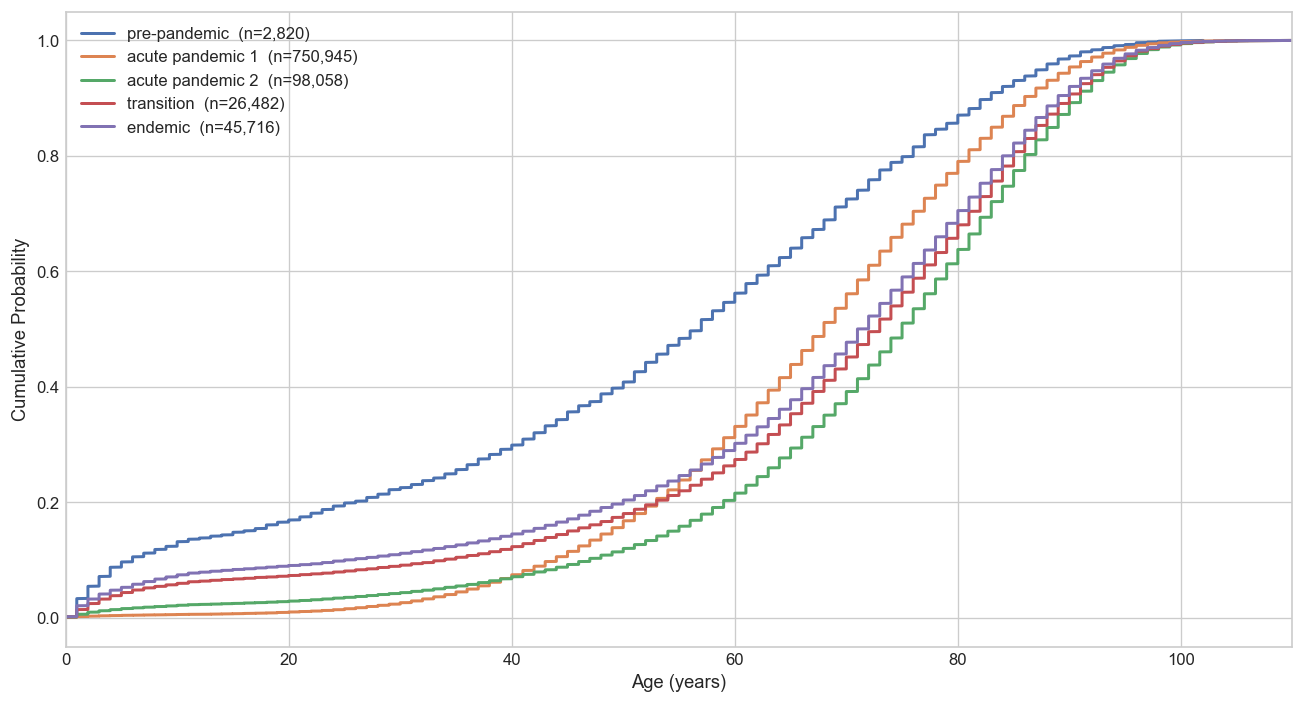

In [9]:
MAX_SAMPLE = 100_000

df_deaths_plot = df[df['death'] == True].copy()

fig, ax = plt.subplots(figsize=(11, 6))

ecdf_deaths = {}
for period in PERIOD_ORDER:
    subset = df_deaths_plot[df_deaths_plot['period'] == period]['age'].dropna()
    n_orig = len(subset)
    if n_orig > MAX_SAMPLE:
        subset = subset.sample(MAX_SAMPLE, random_state=42)
    x = np.sort(subset.values)
    y = np.arange(1, len(x) + 1) / len(x)
    ecdf_deaths[period] = (x, y, n_orig)
    ax.plot(x, y, label=f'{period}  (n={n_orig:,})',
            color=PERIOD_COLORS[period], linewidth=1.8)

ax.set_xlabel('Age (years)')
ax.set_ylabel('Cumulative Probability')
ax.set_xlim(0, 110)
ax.legend(loc='upper left', framealpha=0.9)

plt.tight_layout()
out5 = FIG_DIR / 'fig5_ecdf_deaths_periods.png'
plt.savefig(out5, dpi=120, bbox_inches='tight')
plt.show()

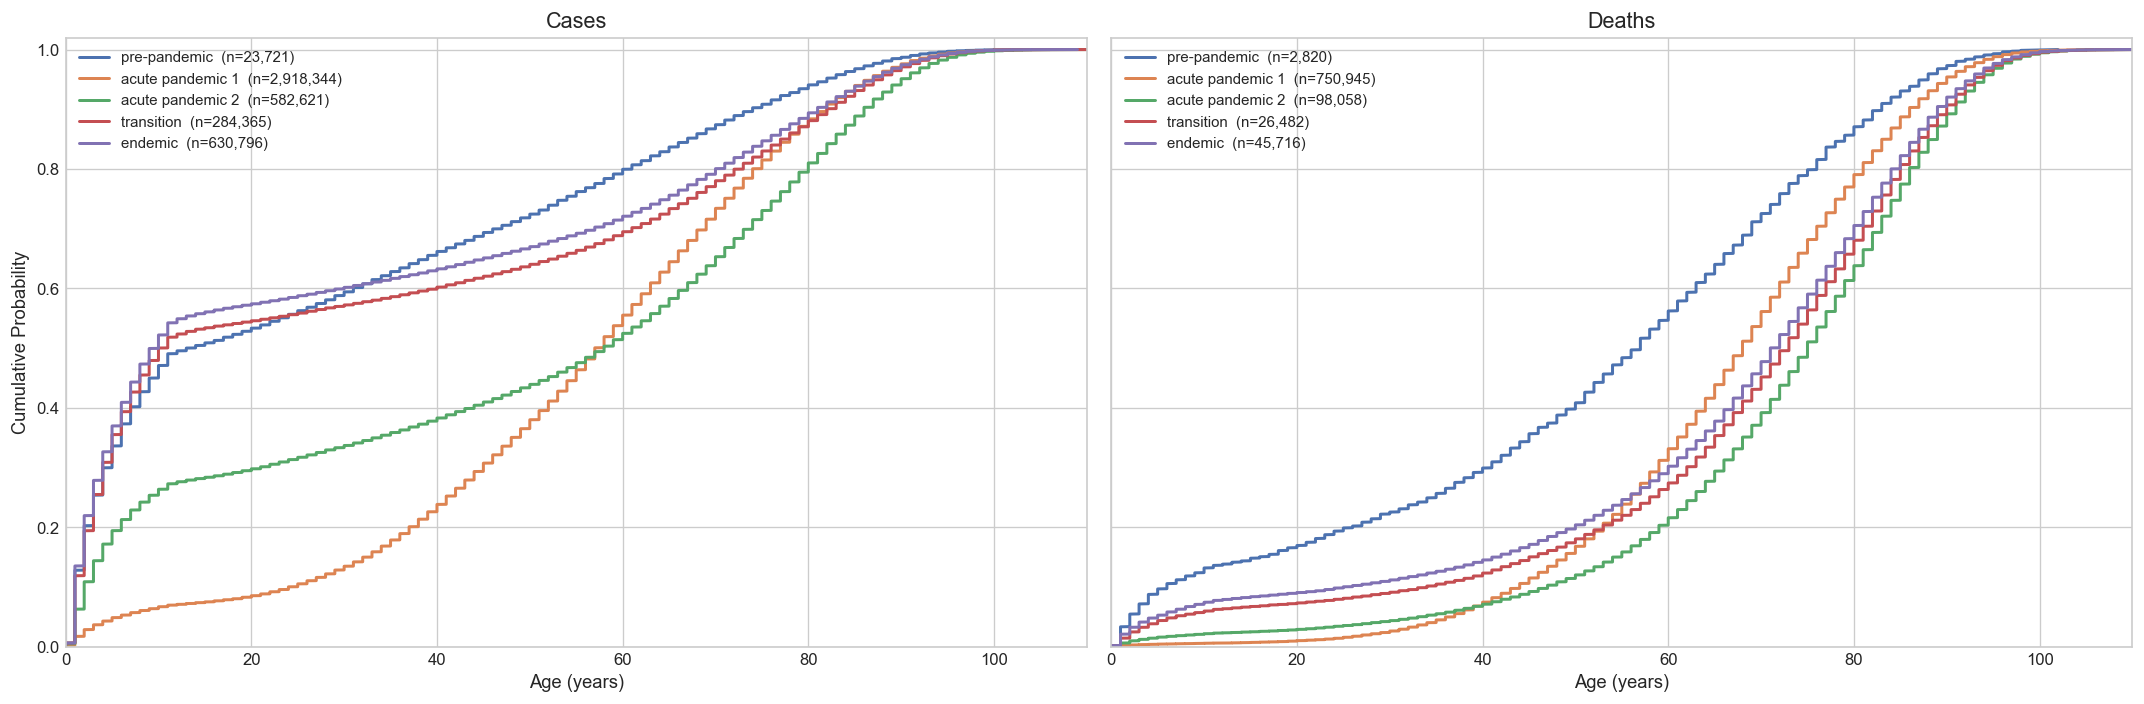

In [10]:
# Requires ecdf_cases (Figure 3) and ecdf_deaths (Figure 5) to be computed
fig, (ax_cases, ax_deaths) = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

# ── Left: ECDFs of cases ─────────────────────────────────────────────────
for period in PERIOD_ORDER:
    x, y, n_orig = ecdf_cases[period]
    ax_cases.plot(x, y, label=f'{period}  (n={n_orig:,})',
                  color=PERIOD_COLORS[period], linewidth=1.8)

ax_cases.set_xlabel('Age (years)')
ax_cases.set_ylabel('Cumulative Probability')
ax_cases.set_title('Cases')
ax_cases.set_xlim(0, 110)
ax_cases.set_ylim(0, 1.02)
ax_cases.legend(loc='upper left', fontsize=9, framealpha=0.9)

# ── Right: ECDFs of deaths ───────────────────────────────────────────────
for period in PERIOD_ORDER:
    x, y, n_orig = ecdf_deaths[period]
    ax_deaths.plot(x, y, label=f'{period}  (n={n_orig:,})',
                   color=PERIOD_COLORS[period], linewidth=1.8)

ax_deaths.set_xlabel('Age (years)')
ax_deaths.set_title('Deaths')
ax_deaths.set_xlim(0, 110)
ax_deaths.legend(loc='upper left', fontsize=9, framealpha=0.9)


plt.tight_layout()
out6 = FIG_DIR / 'fig6_ecdf_cases_vs_deaths.png'
plt.savefig(out6, dpi=120, bbox_inches='tight')
plt.show()

## Figure 7 — Absolute Counts by Age and Period

Complement to Figure 6: instead of cumulative probability, it shows the **absolute number** of cases (left) and deaths (right) in each 5-year age band.

The y axis in absolute scale highlights the difference in magnitude between the periods — acute pandemic 1 dominates in volume — and shows where each period concentrates its cases and deaths in terms of actual counts.

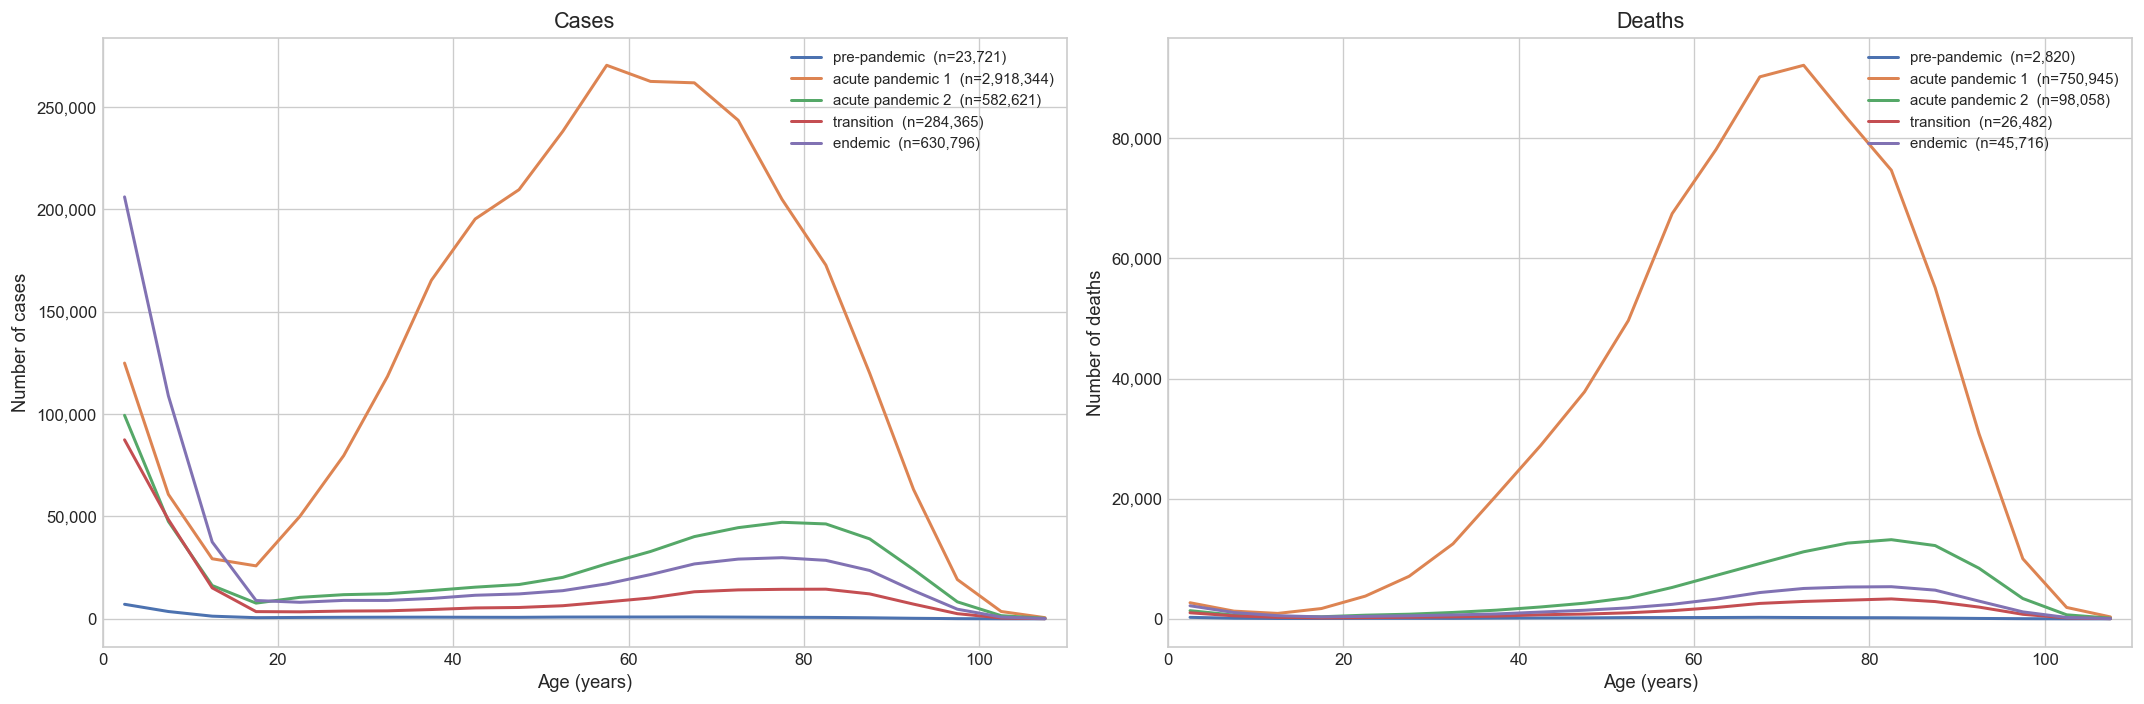

In [11]:
age_bins = np.arange(0, 113, 5)   # 5-year bands: [0,5), [5,10), ..., [105,110)
age_mids = age_bins[:-1] + 2.5    # center of each band

fig, (ax_cases, ax_deaths) = plt.subplots(1, 2, figsize=(18, 6))

# ── Left: count of cases per age band ────────────────────────────────────
for period in PERIOD_ORDER:
    subset = df[df['period'] == period]['age'].dropna()
    counts, _ = np.histogram(subset.values, bins=age_bins)
    ax_cases.plot(age_mids, counts, label=f'{period}  (n={len(subset):,})',
                  color=PERIOD_COLORS[period], linewidth=1.8)

ax_cases.set_xlabel('Age (years)')
ax_cases.set_ylabel('Number of cases')
ax_cases.set_title('Cases')
ax_cases.set_xlim(0, 110)
ax_cases.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax_cases.legend(loc='upper right', fontsize=9, framealpha=0.9)

# ── Right: count of deaths per age band ──────────────────────────────────
df_ob = df[df['death'] == True]
for period in PERIOD_ORDER:
    subset = df_ob[df_ob['period'] == period]['age'].dropna()
    counts, _ = np.histogram(subset.values, bins=age_bins)
    ax_deaths.plot(age_mids, counts, label=f'{period}  (n={len(subset):,})',
                   color=PERIOD_COLORS[period], linewidth=1.8)

ax_deaths.set_xlabel('Age (years)')
ax_deaths.set_ylabel('Number of deaths')
ax_deaths.set_title('Deaths')
ax_deaths.set_xlim(0, 110)
ax_deaths.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax_deaths.legend(loc='upper right', fontsize=9, framealpha=0.9)


plt.tight_layout()
out7 = FIG_DIR / 'fig7_absolute_counts_by_age.png'
plt.savefig(out7, dpi=120, bbox_inches='tight')
plt.show()

## Figure 8 — Bars of Cases and Deaths by Age Band and Period

Grid with one row for cases and one for deaths.
Each column is a period, with bars in 5-year age bands.
The y axis is shared per row (same scale for all periods of cases, and the same scale for all periods of deaths), allowing a direct comparison of magnitude.

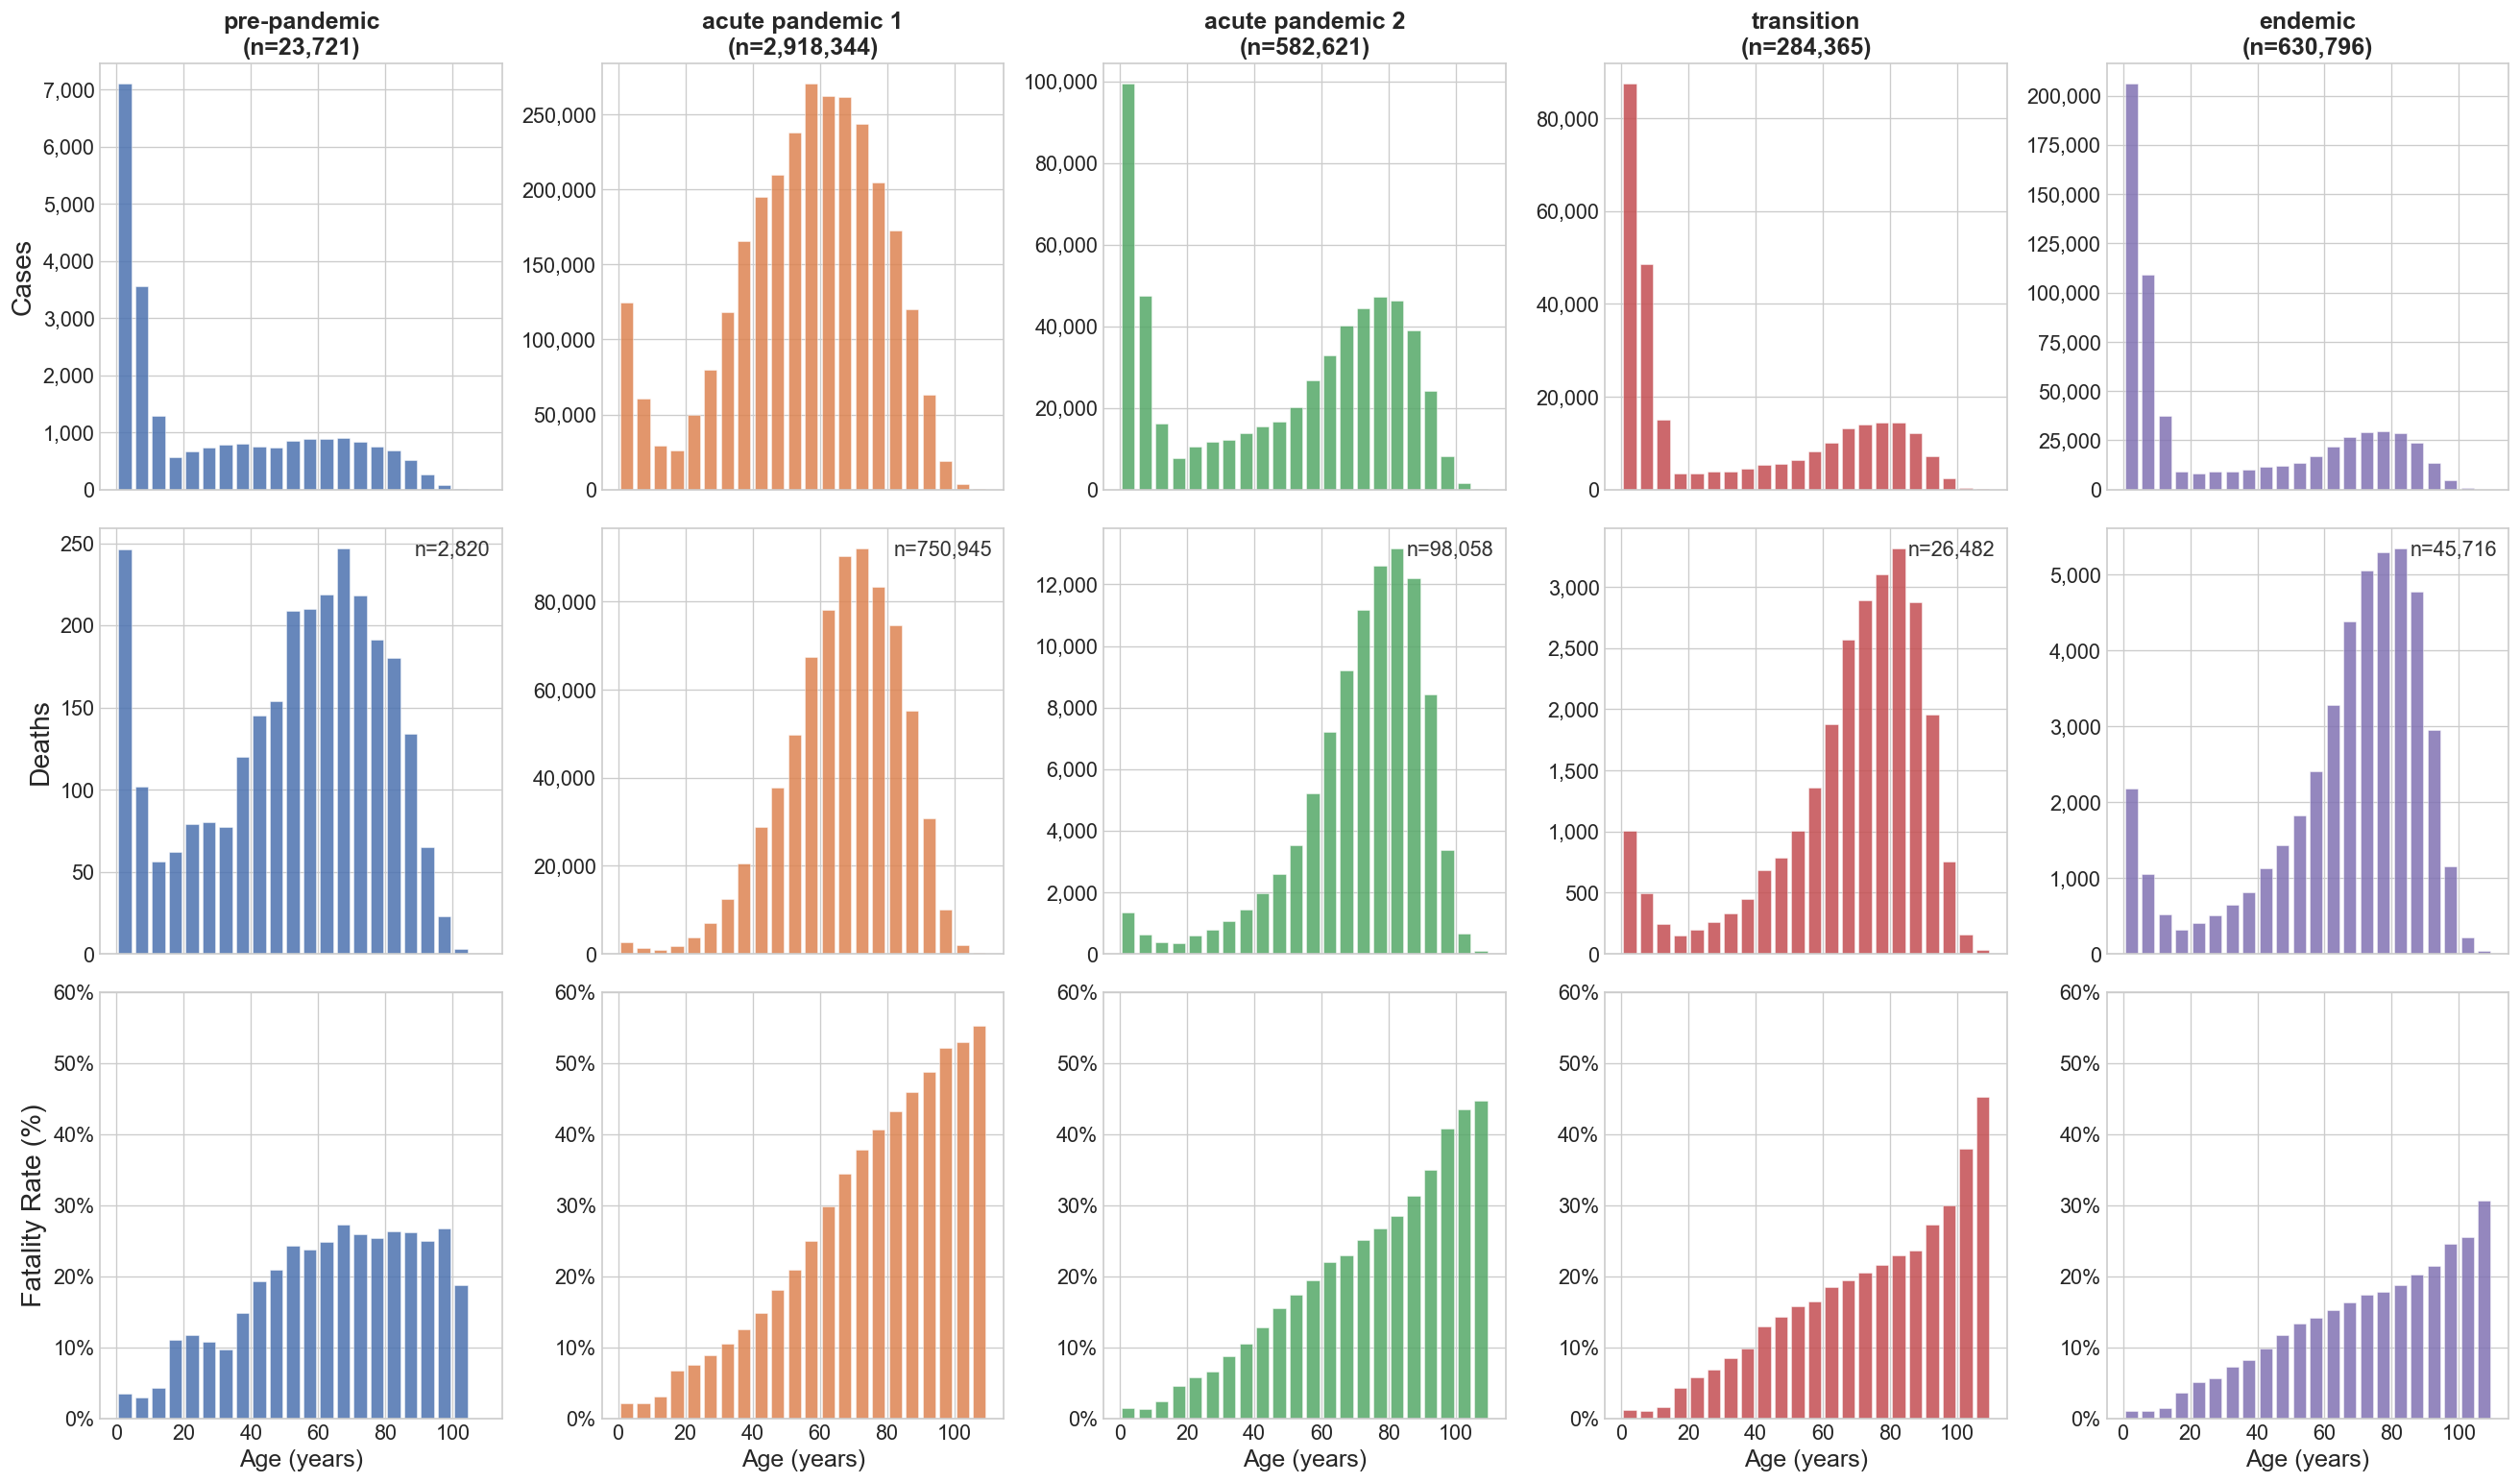

In [12]:
age_bins  = np.arange(0, 113, 5)
age_mids  = age_bins[:-1] + 2.5
bar_width = 3.8

df_ob = df[df['death'] == True]

fig, axes = plt.subplots(3, 5, figsize=(22, 13),
                         sharex=True)

for col, period in enumerate(PERIOD_ORDER):
    color = PERIOD_COLORS[period]

    # ── row 0: cases ─────────────────────────────────────────────────────
    ax = axes[0, col]
    sub_c = df[df['period'] == period]['age'].dropna()
    counts_c, _ = np.histogram(sub_c.values, bins=age_bins)
    ax.bar(age_mids, counts_c, width=bar_width,
           color=color, alpha=0.85, edgecolor='white', linewidth=0.3)
    ax.set_title(f'{period}\n(n={len(sub_c):,})', fontsize=15, fontweight='bold')
    #ax.set_ylim(0, 300_000)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))
    ax.tick_params(axis='both', labelsize=13)

    # ── row 1: deaths ────────────────────────────────────────────────────
    ax = axes[1, col]
    sub_o = df_ob[df_ob['period'] == period]['age'].dropna()
    counts_o, _ = np.histogram(sub_o.values, bins=age_bins)
    ax.bar(age_mids, counts_o, width=bar_width,
           color=color, alpha=0.85, edgecolor='white', linewidth=0.3)
    ax.text(0.97, 0.97, f'n={len(sub_o):,}',
            transform=ax.transAxes, ha='right', va='top', fontsize=13,
            color='#333333')
    #ax.set_ylim(0, 100_000)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{int(x):,}'))
    ax.tick_params(axis='both', labelsize=13)

    # ── row 2: % deaths / cases ──────────────────────────────────────────
    ax = axes[2, col]
    with np.errstate(invalid='ignore', divide='ignore'):
        pct = np.where(counts_c > 0, counts_o / counts_c * 100, np.nan)
    ax.bar(age_mids, pct, width=bar_width,
           color=color, alpha=0.85, edgecolor='white', linewidth=0.3)
    ax.set_xlabel('Age (years)', fontsize=15)
    ax.set_ylim(0, 60)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}%'))
    ax.tick_params(axis='both', labelsize=13)

# row labels
axes[0, 0].set_ylabel('Cases', fontsize=17)
axes[1, 0].set_ylabel('Deaths', fontsize=17)
axes[2, 0].set_ylabel('Fatality Rate (%)', fontsize=17)


plt.tight_layout()
out8 = FIG_DIR / 'fig8_bars_cases_deaths_by_age.png'
plt.savefig(out8, dpi=120, bbox_inches='tight')
plt.show()

In [13]:
# Table of age quantiles of deaths per period
df_deaths_tbl = df[df['death'] == True].copy()

rows_ob = []
for period in PERIOD_ORDER:
    sub = df_deaths_tbl[df_deaths_tbl['period'] == period]['age'].dropna()
    n = len(sub)
    rows_ob.append({
        'Period': period,
        'N Deaths': n,
        'Median Age': round(float(sub.median()), 1) if n > 0 else float('nan'),
        'P25': round(float(sub.quantile(0.25)), 1) if n > 0 else float('nan'),
        'P75': round(float(sub.quantile(0.75)), 1) if n > 0 else float('nan'),
        'P95': round(float(sub.quantile(0.95)), 1) if n > 0 else float('nan'),
        'Mean Age': round(float(sub.mean()), 1) if n > 0 else float('nan'),
        'Std Dev': round(float(sub.std()), 1) if n > 0 else float('nan'),
    })

table_deaths = pd.DataFrame(rows_ob).set_index('Period')
csv_ob = TABLE_DIR / 'table_death_age_quantiles_periods.csv'
table_deaths.to_csv(csv_ob)
table_deaths

,N Deaths,Median Age,P25,P75,P95,Mean Age,Std Dev
Period,,,,,,,
pre-pandemic,2820,57.0,35.0,72.0,88.0,51.6,26.3
acute pandemic 1,750945,68.0,56.0,79.0,90.0,66.3,16.6
acute pandemic 2,98058,75.0,63.0,85.0,94.0,71.3,19.0
transition,26482,73.0,58.0,83.0,93.0,67.0,23.2
endemic,45716,71.0,56.0,82.0,93.0,65.1,24.4


## Main Findings — Update with 5 Periods

### Age shift of cases (Figure 3)

- **Massive initial shift**: D(pre-pandemic vs acute pandemic 1) captures the largest disruption — the arrival of SARS-CoV-2 moved the age profile of cases from seasonal SARS (mostly children) to a concentration at ages 50–70.
- **Younger cases with Omicron**: the ECDF of acute pandemic 2 shifts towards younger ages relative to acute pandemic 1, reflecting the higher transmissibility of Omicron in vaccinated middle-aged populations.
- **Post-pandemic return**: in the endemic period, the ECDF returns to the pre-pandemic pattern, with most cases in children — consistent with the seasonal circulation of RSV and influenza.

### Different dynamics for cases and deaths (Figure 6)

- **Deaths resist the shift to younger ages**: while the ECDFs of cases in acute pandemic 2 move to younger ages, the ECDFs of deaths remain concentrated at advanced ages (≥70 years). Vaccine protection in older adults dampened mortality even with a surge of young cases.
- **Higher median age of deaths in the Omicron era**: the median age of deaths is higher in acute pandemic 2 than in acute pandemic 1 — immunity concentrated the residual mortality in the oldest and most comorbid patients.
- **D(acute pandemic 1 vs 2) is smaller for deaths than for cases**: evidence that Omicron changed the age profile of hospitalized patients more than that of those who died.

### Implications for fairness and distribution shift

- A model trained on acute pandemic 1 (pre-Omicron) and applied to acute pandemic 2 would face distribution shift in the cases, but a smaller shift in the deaths — biasing the calibration of the outcome probability.
- Explicitly separating the two acute pandemic periods makes it possible to evaluate whether triage algorithms learned patterns specific to each dominant strain, and to quantify the impact of the shift on performance and fairness across age and racial groups.

## Section 9: Concept Shift — Case Fatality by Age Band

**Concept shift** happens when the relationship between the features and the target changes between periods, even if the feature distribution stays stable. Here we investigate whether the relationship `age → P(death)` changed across the five epidemiological periods.

If the case fatality curves by age band cross or diverge between periods, we have direct visual evidence of concept shift — a model trained on one period will be miscalibrated on another.

### Preparation: age band and case fatality table

We create the `age_band` column (5 ordered categories) and compute `P(death | age_band, period)` with `groupby`, discarding records with an unknown outcome (null `death`).

In [14]:
# Age band (5 ordered groups)
_bins   = [0, 20, 40, 60, 80, 111]
_labels = ['0-19', '20-39', '40-59', '60-79', '80+']
df['age_band'] = pd.cut(
    df['age'], bins=_bins, labels=_labels, right=False, ordered=True
)

# Defined outcomes only
df_def = df[df['death'].notna()].copy()

# Case fatality per band × period via groupby
grp = (
    df_def.groupby(['age_band', 'period'], observed=True)['death']
    .agg(N='count', n_deaths='sum')
    .reset_index()
)
grp['cfr_pct'] = grp['n_deaths'] / grp['N'] * 100

# Export table
csv_let = TABLE_DIR / 'table_cfr_age_band_period.csv'
grp.to_csv(csv_let, index=False)
grp

,age_band,period,N,n_deaths,cfr_pct
0,0-19,pre-pandemic,11331,466,4.112611
1,0-19,acute pandemic 1,209644,6577,3.137223
2,0-19,acute pandemic 2,152302,2705,1.776076
3,0-19,transition,143785,1896,1.318635
4,0-19,endemic,335582,4064,1.21103
5,20-39,pre-pandemic,2731,356,13.035518
6,20-39,acute pandemic 1,364032,43977,12.080531
7,20-39,acute pandemic 2,39915,3882,9.725667
8,20-39,transition,13758,1231,8.947521
9,20-39,endemic,31382,2375,7.568033


### Figure 8a — Case Fatality Lines by Age Band

Each line is a period. The x axis runs through the five ordered age bands; the y axis shows the case fatality rate (%). **Crossings or divergences between lines are the visual signature of concept shift**: the age→death relationship changed non-uniformly between periods.

Acute pandemic 1 (pre-Omicron) is expected to have a much higher case fatality in every band than acute pandemic 2 (Omicron), and the size of this drop is expected to vary by age band — showing that the shift is not only in level, but in shape.

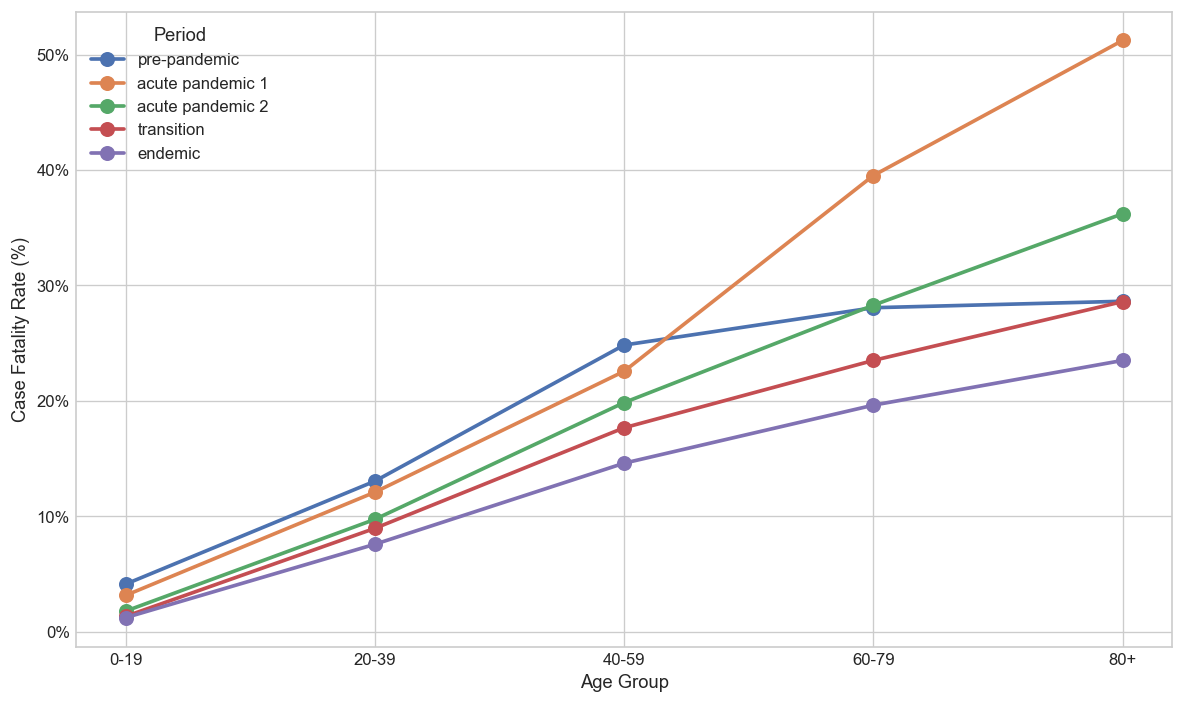

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))

for period in PERIOD_ORDER:
    sub = grp[grp['period'] == period].sort_values('age_band')
    ax.plot(sub['age_band'].astype(str), sub['cfr_pct'],
            marker='o', linewidth=2.2, markersize=8,
            label=period, color=PERIOD_COLORS[period])

ax.set_xlabel('Age Group')
ax.set_ylabel('Case Fatality Rate (%)')
ax.legend(title='Period', framealpha=0.9)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}%'))

plt.tight_layout()
out8a = FIG_DIR / 'fig8a_cfr_by_age_band.png'
plt.savefig(out8a, dpi=120, bbox_inches='tight')
plt.show()

### Figure 8b — Case Fatality Heatmap (Age Band × Period)

The heatmap complements Figure 8a with the exact values in each cell. The color intensity maps the case fatality rate (%), making it easier to read patterns by band and by period at the same time.

Bands with the strongest **concept shift** appear as rows where the color changes a lot from left (pre-pandemic) to right (endemic).

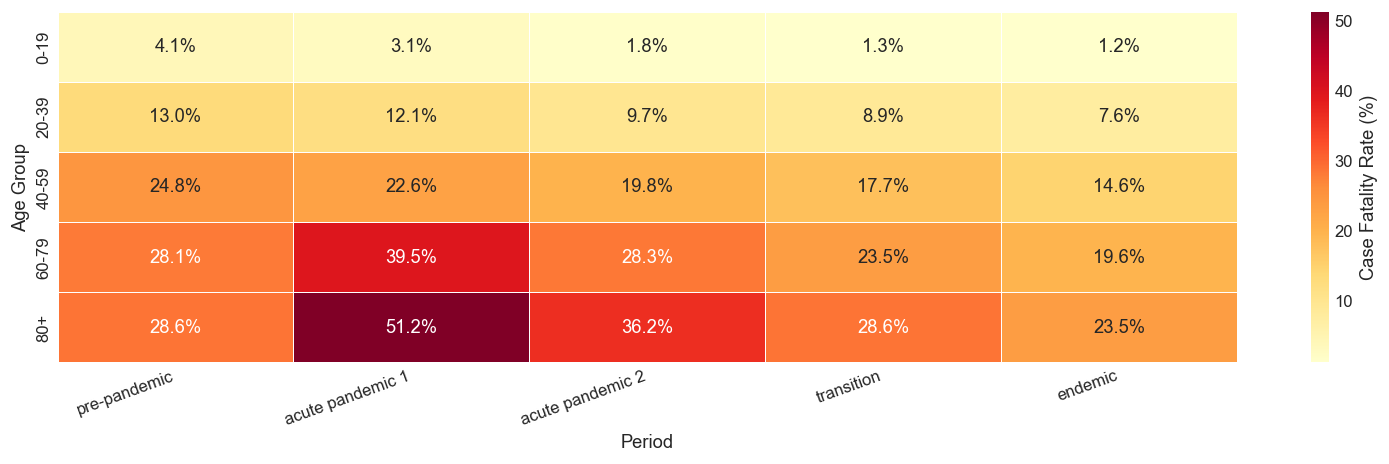

In [16]:
pivot = (
    grp.pivot(index='age_band', columns='period', values='cfr_pct')
    [PERIOD_ORDER]
    .astype(float)
)

annot_str = pivot.map(lambda v: f'{v:.1f}%' if pd.notna(v) else '')

fig, ax = plt.subplots(figsize=(13, 4))
sns.heatmap(
    pivot,
    annot=annot_str,
    fmt='',
    cmap='YlOrRd',
    ax=ax,
    linewidths=0.5,
    cbar_kws={'label': 'Case Fatality Rate (%)'}
)
ax.set_xlabel('Period')
ax.set_ylabel('Age Group')
plt.setp(ax.get_xticklabels(), rotation=20, ha='right')

plt.tight_layout()
out8b = FIG_DIR / 'fig8b_cfr_heatmap.png'
plt.savefig(out8b, dpi=120, bbox_inches='tight')
plt.show()

### Interpretation — Concept Shift in the Age → Death Relationship

- **Crossing curves confirm a structural concept shift**: the lines of different periods are not parallel — the size of the drop in case fatality between acute pandemic 1 and acute pandemic 2 varies by age band. This means that a model trained on acute pandemic 1 not only overestimates the overall risk in acute pandemic 2, but does so *differently* by age, introducing systematic bias in the younger groups.

- **Bands 60–79 and 80+ show the largest absolute shift between acute pandemic 1 and acute pandemic 2**: in these bands, vaccination had the largest relative protective effect, lowering case fatality more sharply than in the younger bands. As a result, the "slope" of the age→death curve becomes steeper in the Omicron era, with the 80+ band keeping a high case fatality while the intermediate bands fall more.

- **The endemic and transition periods converge to the pre-pandemic pattern in the younger bands, but diverge in the older ones**: in bands 0–19 and 20–39 the case fatality returns to levels close to the pre-pandemic one, but in bands 60–79 and 80+ it stays above the pre-pandemic level — reflecting that endemic SARS-CoV-2 still adds excess mortality among older adults, even with established hybrid immunity.